# WeedSAM — 02: Grad-CAM and SAM 2 Segmentation

## Project Overview

This notebook investigates weakly supervised crop and weed segmentation using Grad-CAM and SAM 2.

We reuse the trained multi-label ResNet18 classifier from Notebook 01 to generate class-specific activation maps without pixel-level supervision.

Our objective is to compare initial Grad-CAM pseudo-masks with SAM 2 refined masks.

## 1. Environment Setup

We restore the trained classification model, experiment configuration, class-specific thresholds and dataset splits from persistent Google Drive storage.

The original training configuration is preserved to ensure reproducibility and consistency across notebooks.

In [1]:
%pip install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=ac4f30f9417b99ab1296c2ae2ece72d7058c5ae41a0eea6a2ad2f0172cb5c013
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from torchvision.models import resnet18


# Project paths
PROJECT_DIR = Path("/kaggle/input/datasets/youssefennagui/weedsam-data/WeedSAM")
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "images"
MASK_DIR = DATA_DIR / "labelIds"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Project directory:", PROJECT_DIR)
print("Project available:", PROJECT_DIR.exists())


Device: cuda
Project directory: /kaggle/input/datasets/youssefennagui/weedsam-data/WeedSAM
Project available: True


In [3]:

# Load experiment configuration
with open(RESULTS_DIR / "config.json") as f:
    config = json.load(f)

class_names = config["class_names"]
thresholds = np.array(config["thresholds"])
IMG_SIZE = config["image_size"]

# Restore dataset splits
train_df = pd.read_csv(RESULTS_DIR / "train.csv")
val_df = pd.read_csv(RESULTS_DIR / "val.csv")
test_df = pd.read_csv(RESULTS_DIR / "test.csv")

# Restore trained ResNet18
model = resnet18(weights=None)
model.fc = nn.Linear(512, len(class_names))

model.load_state_dict(torch.load(
    RESULTS_DIR / "weedsam_resnet18.pth",
    map_location=device,
    weights_only=True
))

model = model.to(device)
model.eval()

# Preserve the original preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ResNet18 restored successfully!")
print("Classes:", class_names)
print("Thresholds:", thresholds)
print("Image size:", IMG_SIZE)
print("Best epoch:", config["best_epoch"])
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

ResNet18 restored successfully!
Classes: ['Maize', 'Meadow-grass', 'Creeping thistle']
Thresholds: [0.1  0.1  0.15]
Image size: 448
Best epoch: 8
Validation images: 44
Test images: 46


## 2. Class-Specific Grad-CAM Localization

### 2.1 Grad-CAM Heatmap Generation

Gradient-weighted Class Activation Mapping (Grad-CAM) is used to identify image regions that contribute to a specific class prediction.

We select the final residual block of ResNet18 as our target layer.

For each predicted plant category, Grad-CAM computes the gradients of the corresponding class logit with respect to the convolutional feature maps.

The resulting heatmap highlights discriminative regions and is resized to the original image resolution.

In this initial experiment, we use validation images to inspect localization quality before generating pseudo-masks.

Ground truth segmentation masks are used only for visual comparison, not for Grad-CAM generation.

In [4]:

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Select the target convolutional layer
target_layers = [model.layer4[-1]]

def generate_gradcam(image_name, class_idx):

    # Load the original image
    image = Image.open(
        IMAGE_DIR / image_name
    ).convert("RGB")

    rgb = np.array(image)
    width, height = image.size

    # Prepare model input
    x = eval_transform(image).unsqueeze(0).to(device)

    # Generate class-specific activation map
    with GradCAM(
        model=model,
        target_layers=target_layers
    ) as cam:

        heatmap = cam(
            input_tensor=x,
            targets=[ClassifierOutputTarget(class_idx)]
        )[0]

    # Resize CAM to original image resolution
    heatmap = np.array(
        Image.fromarray(heatmap).resize(
            (width, height),
            Image.Resampling.BILINEAR
        )
    )

    # Generate visualization
    overlay = show_cam_on_image(
        rgb.astype(np.float32) / 255.0,
        heatmap,
        use_rgb=True
    )

    return rgb, heatmap, overlay

print("Grad-CAM function ready!")

Grad-CAM function ready!


,Class,Probability,Threshold,Prediction,Ground Truth
0,Maize,0.1539,0.10,1,1
1,Meadow-grass,0.5902,0.10,1,0
2,Creeping thistle,0.9710,0.15,1,1


Image: ave-0079-0010.jpg
Predicted classes: ['Maize', 'Meadow-grass', 'Creeping thistle']


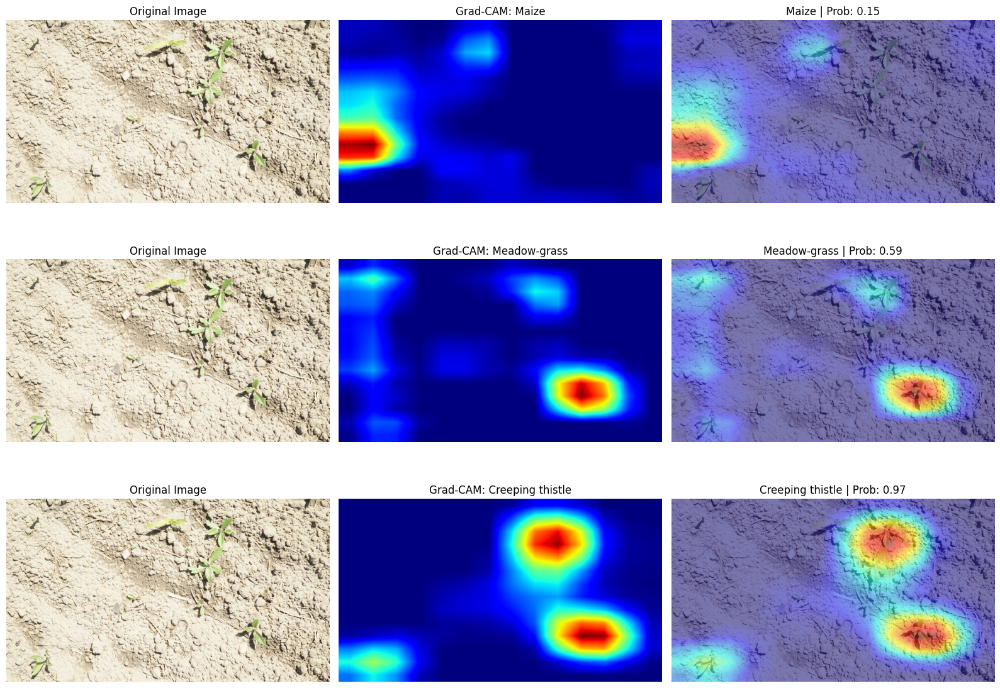

In [5]:

# Select a validation image containing target plants
row = val_df[val_df[class_names].sum(axis=1) > 0].sample(
    1, random_state=42
).iloc[0]

image_name = row["image"]

# Predict plant species
image = Image.open(IMAGE_DIR / image_name).convert("RGB")
x = eval_transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    probs = torch.sigmoid(model(x))[0].cpu().numpy()

predicted_classes = np.where(probs >= thresholds)[0]

# Display predicted and actual labels
display(pd.DataFrame({
    "Class": class_names,
    "Probability": probs,
    "Threshold": thresholds,
    "Prediction": (probs >= thresholds).astype(int),
    "Ground Truth": row[class_names].astype(int).values
}).round(4))

print("Image:", image_name)
print("Predicted classes:", [
    class_names[i] for i in predicted_classes
])

# Generate one Grad-CAM per predicted class
if len(predicted_classes) == 0:
    print("No target class predicted.")
else:
    fig, axes = plt.subplots(
        len(predicted_classes), 3,
        figsize=(16, 4 * len(predicted_classes)),
        squeeze=False
    )

    for j, idx in enumerate(predicted_classes):
        rgb, heatmap, overlay = generate_gradcam(
            image_name, int(idx)
        )

        axes[j, 0].imshow(rgb)
        axes[j, 0].set_title("Original Image")

        axes[j, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
        axes[j, 1].set_title(f"Grad-CAM: {class_names[idx]}")

        axes[j, 2].imshow(overlay)
        axes[j, 2].set_title(
            f"{class_names[idx]} | Prob: {probs[idx]:.2f}"
        )

        for ax in axes[j]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

### 2.2 Pseudo-mask Generation and Threshold Selection

Grad-CAM heatmaps highlight discriminative regions but do not provide precise object boundaries.

To generate initial segmentation pseudo-masks, we apply a threshold to each class-specific activation map.

Our approach consists of:

- Generating activation maps for predicted plant categories.
- Converting continuous activation values into binary masks.
- Combining class-specific masks into a semantic segmentation map.
- Selecting the CAM threshold using validation ground truth masks and mean Intersection over Union (mIoU).

When multiple classes overlap, the class with the highest activation value is selected.

Non-target vegetation and unidentified regions are ignored during evaluation.

These initial pseudo-masks will serve as the baseline for SAM 2 refinement.

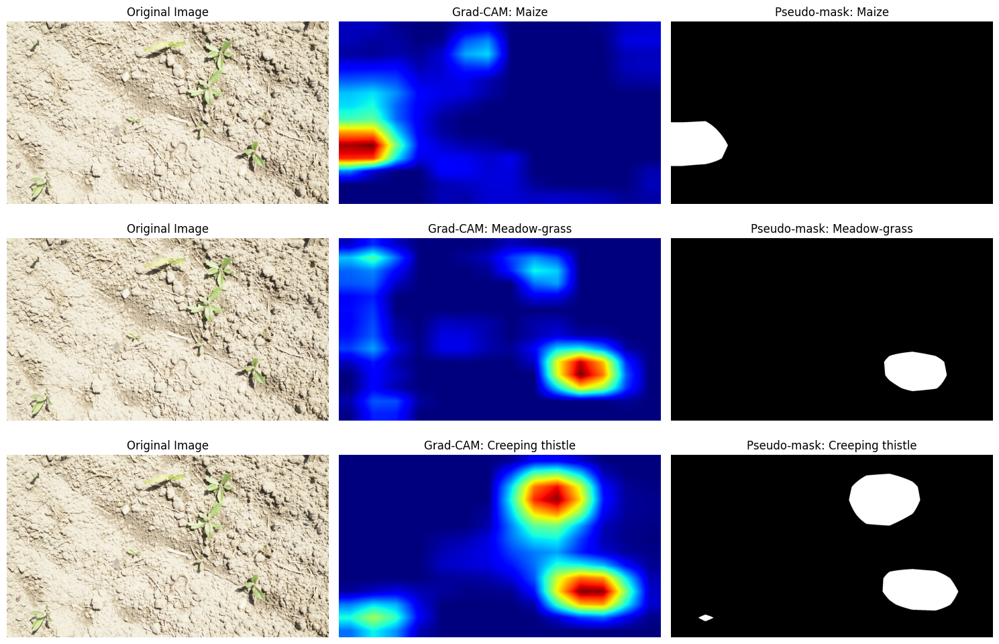

In [6]:

# Generate CAMs for all predicted classes
def get_image_cams(image_name):
    image = Image.open(IMAGE_DIR / image_name).convert("RGB")
    rgb = np.array(image)
    x = eval_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        probs = torch.sigmoid(model(x))[0].cpu().numpy()

    cams = np.zeros(
        (len(class_names), *rgb.shape[:2]),
        dtype=np.float32
    )

    for idx in np.where(probs >= thresholds)[0]:
        _, cams[idx], _ = generate_gradcam(image_name, int(idx))

    return rgb, cams, probs


# Convert CAMs into a semantic pseudo-mask
def create_pseudo_mask(cams, tau=0.5):
    mask = (cams.argmax(axis=0) + 1).astype(np.uint8)
    mask[cams.max(axis=0) < tau] = 0
    return mask


# Test on the previously selected image
rgb, cams, probs = get_image_cams(image_name)

CAM_THRESHOLD = 0.5

fig, axes = plt.subplots(
    len(class_names), 3, figsize=(15, 10)
)

for i, name in enumerate(class_names):
    binary_mask = cams[i] >= CAM_THRESHOLD

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(cams[i], cmap="jet", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Grad-CAM: {name}")

    axes[i, 2].imshow(binary_mask, cmap="gray")
    axes[i, 2].set_title(f"Pseudo-mask: {name}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:

# Load ground truth with target class mapping
def load_target_mask(image_name):
    path = MASK_DIR / f"{Path(image_name).stem}.png"
    raw_mask = np.array(Image.open(path))

    mask = np.full(raw_mask.shape, 255, dtype=np.uint8)
    mask[raw_mask == 0] = 0

    for i, name in enumerate(class_names):
        ids = config["target_classes"][name]
        mask[np.isin(raw_mask, ids)] = i + 1

    return mask


# Candidate CAM thresholds
cam_thresholds = np.arange(0.2, 0.81, 0.1)

intersections = np.zeros((len(cam_thresholds), 3))
unions = np.zeros_like(intersections)

# Evaluate on validation images only
for n, name in enumerate(val_df["image"], 1):

    _, cams, _ = get_image_cams(name)
    gt = load_target_mask(name)

    valid = gt != 255

    for j, tau in enumerate(cam_thresholds):
        pred = create_pseudo_mask(cams, tau)

        for c in range(1, 4):
            p = (pred == c) & valid
            g = (gt == c) & valid

            intersections[j, c-1] += (p & g).sum()
            unions[j, c-1] += (p | g).sum()

    if n % 10 == 0:
        print(f"Processed: {n}/{len(val_df)}")

# Compute IoU per class and mean foreground IoU
ious = intersections / np.maximum(unions, 1)

cam_results = pd.DataFrame(
    ious, columns=class_names
)

cam_results["Threshold"] = cam_thresholds
cam_results["mIoU"] = ious.mean(axis=1)

display(cam_results.round(4))

best_idx = cam_results["mIoU"].idxmax()
BEST_CAM_THRESHOLD = float(cam_thresholds[best_idx])

print("Best CAM threshold:", round(BEST_CAM_THRESHOLD, 2))
print("Best validation mIoU:", round(ious[best_idx].mean(), 4))

# Save threshold results
cam_results.to_csv(
    RESULTS_DIR / "cam_threshold_evaluation.csv",
    index=False
)

with open(RESULTS_DIR / "cam_config.json", "w") as f:
    json.dump({"cam_threshold": BEST_CAM_THRESHOLD}, f)

# Visualize threshold performance
plt.plot(cam_thresholds, ious.mean(axis=1), marker="o")
plt.xlabel("CAM Threshold")
plt.ylabel("Validation mIoU")
plt.title("CAM Threshold Optimization")
plt.grid(alpha=0.3)
plt.show()

Processed: 10/44
Processed: 20/44
Processed: 30/44
Processed: 40/44


,Maize,Meadow-grass,Creeping thistle,Threshold,mIoU
0,0.0048,0.0019,0.0857,0.2,0.0308
1,0.0059,0.0023,0.1090,0.3,0.0391
2,0.0079,0.0024,0.1319,0.4,0.0474
3,0.0104,0.0029,0.1534,0.5,0.0556
4,0.0128,0.0032,0.1710,0.6,0.0623
5,0.0176,0.0034,0.1743,0.7,0.0651
6,0.0203,0.0029,0.1681,0.8,0.0638


Best CAM threshold: 0.7
Best validation mIoU: 0.0651


OSError: [Errno 30] Read-only file system: '/kaggle/input/datasets/youssefennagui/weedsam-data/WeedSAM/results/cam_threshold_evaluation.csv'

Results saved successfully!
Output directory: /kaggle/working/weedsam_results


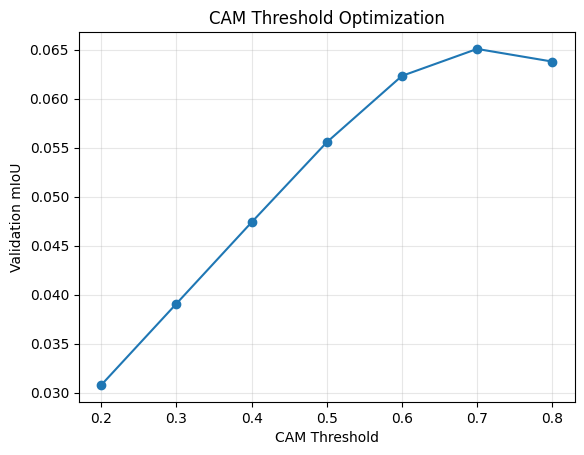

In [8]:

# Create a writable output directory
OUTPUT_DIR = Path("/kaggle/working/weedsam_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save CAM threshold evaluation
cam_results.to_csv(
    OUTPUT_DIR / "cam_threshold_evaluation.csv",
    index=False
)

# Save the optimal CAM threshold
with open(OUTPUT_DIR / "cam_config.json", "w") as f:
    json.dump({
        "cam_threshold": BEST_CAM_THRESHOLD
    }, f, indent=4)

print("Results saved successfully!")
print("Output directory:", OUTPUT_DIR)

# Visualize threshold performance
plt.plot(
    cam_thresholds,
    ious.mean(axis=1),
    marker="o"
)

plt.xlabel("CAM Threshold")
plt.ylabel("Validation mIoU")
plt.title("CAM Threshold Optimization")
plt.grid(alpha=0.3)
plt.show()

### 2.3 Automatic SAM 2 Prompt Generation

To refine Grad-CAM pseudo-masks with SAM 2, we automatically generate spatial prompts from class-specific activation maps.

For each predicted plant category, we:

- Apply the optimized CAM threshold selected on the validation set.
- Extract connected components from the binary activation mask.
- Identify the highest activation point within each component.
- Compute a bounding box around each candidate region.
- Expand the bounding box slightly to allow better object coverage.

Each candidate region is associated with its predicted plant category.

Ground truth bounding boxes, stem coordinates and segmentation masks are not used for prompt generation.

This approach preserves the weakly supervised nature of our localization pipeline.

In [9]:

import cv2

# Generate spatial prompts from a class activation map
def generate_prompts(heatmap, tau, min_area=50, padding=0.15):

    binary = (heatmap >= tau).astype(np.uint8)

    # Extract connected regions
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )

    height, width = heatmap.shape
    prompts = []

    for i in range(1, n):

        x, y, w, h, area = stats[i]

        if area < min_area:
            continue

        # Find the strongest activation point
        region = labels == i
        scores = np.where(region, heatmap, -np.inf)

        py, px = np.unravel_index(
            scores.argmax(), scores.shape
        )

        # Expand the bounding box
        pad_x = int(w * padding)
        pad_y = int(h * padding)

        box = [
            max(0, x - pad_x),
            max(0, y - pad_y),
            min(width - 1, x + w - 1 + pad_x),
            min(height - 1, y + h - 1 + pad_y)
        ]

        prompts.append({
            "point": [int(px), int(py)],
            "box": box,
            "score": float(heatmap[py, px]),
            "area": int(area)
        })

    return prompts


# Generate prompts for the selected image
rgb, cams, probs = get_image_cams(image_name)

all_prompts = {}

for i, name in enumerate(class_names):

    if probs[i] >= thresholds[i]:

        all_prompts[name] = generate_prompts(
            cams[i],
            tau=BEST_CAM_THRESHOLD
        )

        print(f"{name}: {len(all_prompts[name])} regions")


Maize: 1 regions
Meadow-grass: 1 regions
Creeping thistle: 2 regions


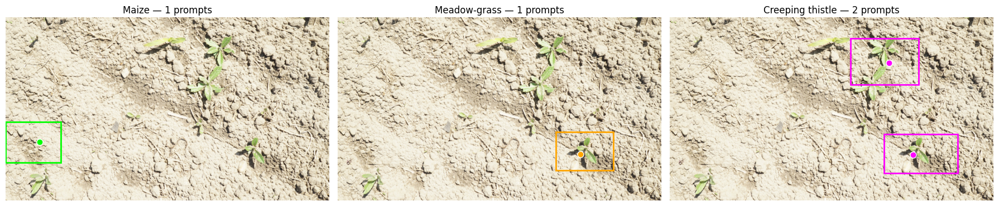

In [10]:

import matplotlib.patches as patches

colors = ["lime", "orange", "magenta"]

fig, axes = plt.subplots(
    1, len(class_names),
    figsize=(18, 6)
)

for i, name in enumerate(class_names):

    ax = axes[i]
    ax.imshow(rgb)

    prompts = all_prompts.get(name, [])

    for prompt in prompts:

        # Draw bounding box
        x1, y1, x2, y2 = prompt["box"]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor=colors[i],
            facecolor="none"
        )

        ax.add_patch(rect)

        # Draw positive point
        px, py = prompt["point"]

        ax.scatter(
            px, py,
            color=colors[i],
            edgecolors="white",
            s=65,
            marker="o"
        )

    ax.set_title(
        f"{name} — {len(prompts)} prompts"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. SAM 2 Mask Refinement

### 3.1 Model Initialization

We use the pretrained Segment Anything Model 2.1 (SAM 2.1) to refine coarse Grad-CAM localization maps into object-level segmentation masks.

For computational efficiency, we select the Hiera Tiny checkpoint.

Our approach consists of:

- Loading the pretrained SAM 2.1 image segmentation model.
- Encoding the original agricultural image.
- Providing automatically generated point and bounding-box prompts.
- Selecting candidate masks based on the predicted mask quality.
- Preserving the plant category associated with each prompt.

SAM 2 is used in zero-shot mode, without additional training or ground truth spatial prompts.

The objective is to determine whether SAM 2 can improve the spatial accuracy of weakly supervised pseudo-masks.

In [11]:

# Install SAM 2
%pip install -q git+https://github.com/facebookresearch/sam2.git

# Download the pretrained checkpoint
from pathlib import Path
import urllib.request

# Kaggle writable directory
CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

SAM_CHECKPOINT = CHECKPOINT_DIR / "sam2.1_hiera_tiny.pt"

checkpoint_url = (
    "https://dl.fbaipublicfiles.com/segment_anything_2/"
    "092824/sam2.1_hiera_tiny.pt"
)

if not SAM_CHECKPOINT.exists():
    urllib.request.urlretrieve(
        checkpoint_url,
        SAM_CHECKPOINT
    )

print("SAM 2.1 checkpoint downloaded!")
print("Checkpoint:", SAM_CHECKPOINT)
print(f"Size: {SAM_CHECKPOINT.stat().st_size / 1e6:.2f} MB")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
SAM 2.1 checkpoint downloaded!
Checkpoint: /kaggle/working/checkpoints/sam2.1_hiera_tiny.pt
Size: 156.01 MB


In [12]:

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# SAM 2.1 configuration
SAM_CONFIG = "configs/sam2.1/sam2.1_hiera_t.yaml"

# Build the pretrained model
sam_model = build_sam2(
    SAM_CONFIG,
    str(SAM_CHECKPOINT),
    device=device
)

sam_model.eval()

# Create image predictor
predictor = SAM2ImagePredictor(sam_model)

# Encode the selected agricultural image
with torch.inference_mode():
    predictor.set_image(rgb)

print("SAM 2.1 Hiera Tiny loaded successfully!")
print("Image encoded successfully!")
print("Device:", device)

SAM 2.1 Hiera Tiny loaded successfully!
Image encoded successfully!
Device: cuda


### 3.2 Prompt-Based Mask Prediction

We use the point and bounding-box prompts generated from Grad-CAM activation maps to guide SAM 2.

For each candidate region, SAM 2 predicts multiple segmentation masks and estimates their quality.

We select the mask with the highest predicted quality score and associate it with the original plant category.

We then compare the coarse CAM-based pseudo-masks with the refined SAM 2 masks.

This qualitative analysis helps identify successful refinements, incorrect prompts, and potential species conflicts.

In [13]:

# Generate one SAM mask for each candidate region
sam_instances = []

with torch.inference_mode():

    for class_idx, name in enumerate(class_names):

        for prompt in all_prompts.get(name, []):

            masks, scores, _ = predictor.predict(
                point_coords=np.array(
                    [prompt["point"]],
                    dtype=np.float32
                ),
                point_labels=np.array([1]),
                box=np.array(
                    prompt["box"],
                    dtype=np.float32
                ),
                multimask_output=True
            )

            # Select the best candidate mask
            best_idx = np.argmax(scores)

            sam_instances.append({
                "class_id": class_idx + 1,
                "class_name": name,
                "mask": masks[best_idx].astype(bool),
                "sam_score": float(scores[best_idx]),
                "point": prompt["point"],
                "box": prompt["box"]
            })

# Display predicted instances
display(pd.DataFrame([
    {
        "Class": instance["class_name"],
        "SAM Score": instance["sam_score"],
        "Mask Area": instance["mask"].sum()
    }
    for instance in sam_instances
]).round(4))

print("Total predicted masks:", len(sam_instances))

,Class,SAM Score,Mask Area
0,Maize,0.7274,119366
1,Meadow-grass,0.6802,10048
2,Creeping thistle,0.7560,21161
3,Creeping thistle,0.5044,141187


Total predicted masks: 4


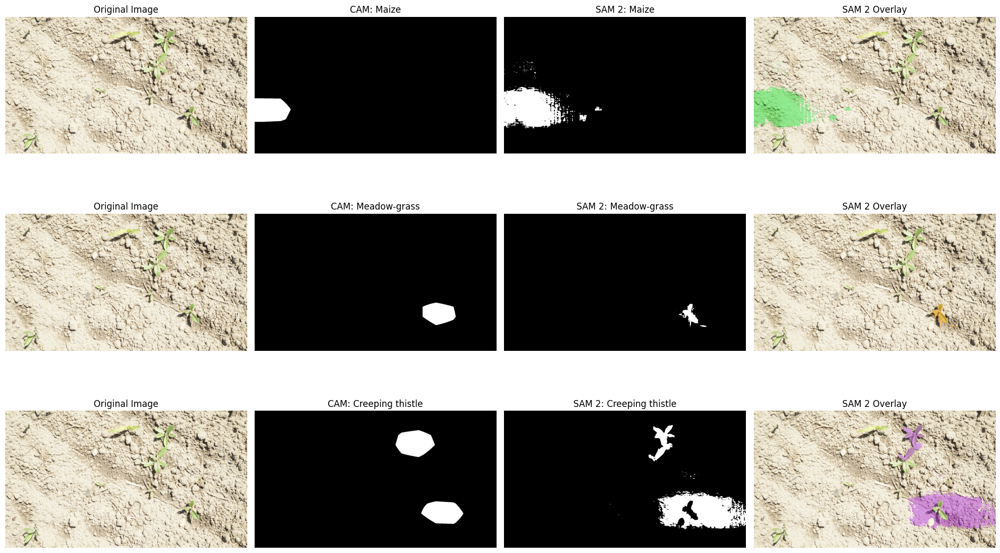

In [14]:
# Before vs After SAM 2

# Compare CAM masks and SAM masks
fig, axes = plt.subplots(
    len(class_names), 4,
    figsize=(19, 4 * len(class_names))
)

colors = [
    [0.1, 0.9, 0.2],
    [1.0, 0.6, 0.0],
    [0.7, 0.2, 0.9]
]

for i, name in enumerate(class_names):

    # Initial CAM mask
    cam_mask = cams[i] >= BEST_CAM_THRESHOLD

    # Combine SAM instances of the same class
    sam_mask = np.zeros(rgb.shape[:2], dtype=bool)

    for instance in sam_instances:
        if instance["class_id"] == i + 1:
            sam_mask |= instance["mask"]

    # Create SAM overlay
    overlay = rgb.astype(np.float32) / 255.0

    overlay[sam_mask] = (
        0.55 * overlay[sam_mask]
        + 0.45 * np.array(colors[i])
    )

    # Display results
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(cam_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"CAM: {name}")

    axes[i, 2].imshow(sam_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"SAM 2: {name}")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("SAM 2 Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 3.3 Semantic Mask Fusion and Conflict Resolution

SAM 2 generates object-level masks from automatically generated Grad-CAM prompts.

However, masks from different plant categories may overlap, resulting in conflicting semantic predictions.

To construct a final semantic segmentation map, we:

- Preserve the predicted plant category of each SAM 2 mask.
- Compute a combined confidence score using the classification probability and SAM 2 mask quality score.
- Resolve overlapping regions by assigning each pixel to the mask with the highest combined confidence.
- Assign unsegmented pixels to the background class.

We then compare the original Grad-CAM pseudo-mask, the SAM 2 refined semantic mask, and the ground truth segmentation.

This experiment investigates whether SAM 2 improves weakly supervised semantic segmentation without using ground truth spatial prompts.

In [15]:

# Fuse SAM 2 masks into a semantic segmentation map
def fuse_sam_masks(instances, probs, image_shape):

    semantic_mask = np.zeros(
        image_shape, dtype=np.uint8
    )

    confidence_map = np.zeros(
        image_shape, dtype=np.float32
    )

    for instance in instances:

        class_id = instance["class_id"]
        mask = instance["mask"].astype(bool)

        # Combine classification and SAM confidence
        score = (
            probs[class_id - 1]
            * instance["sam_score"]
        )

        # Assign pixels to the highest-scoring mask
        update = mask & (score > confidence_map)

        semantic_mask[update] = class_id
        confidence_map[update] = score

    return semantic_mask, confidence_map


# Generate initial and refined semantic masks
cam_semantic = create_pseudo_mask(
    cams, BEST_CAM_THRESHOLD
)

sam_semantic, confidence_map = fuse_sam_masks(
    sam_instances,
    probs,
    rgb.shape[:2]
)

gt = load_target_mask(image_name)

print("CAM mask shape:", cam_semantic.shape)
print("SAM mask shape:", sam_semantic.shape)
print("Ground truth shape:", gt.shape)

print("Predicted class IDs:", np.unique(sam_semantic))


CAM mask shape: (1088, 1920)
SAM mask shape: (1088, 1920)
Ground truth shape: (1088, 1920)
Predicted class IDs: [0 1 2 3]


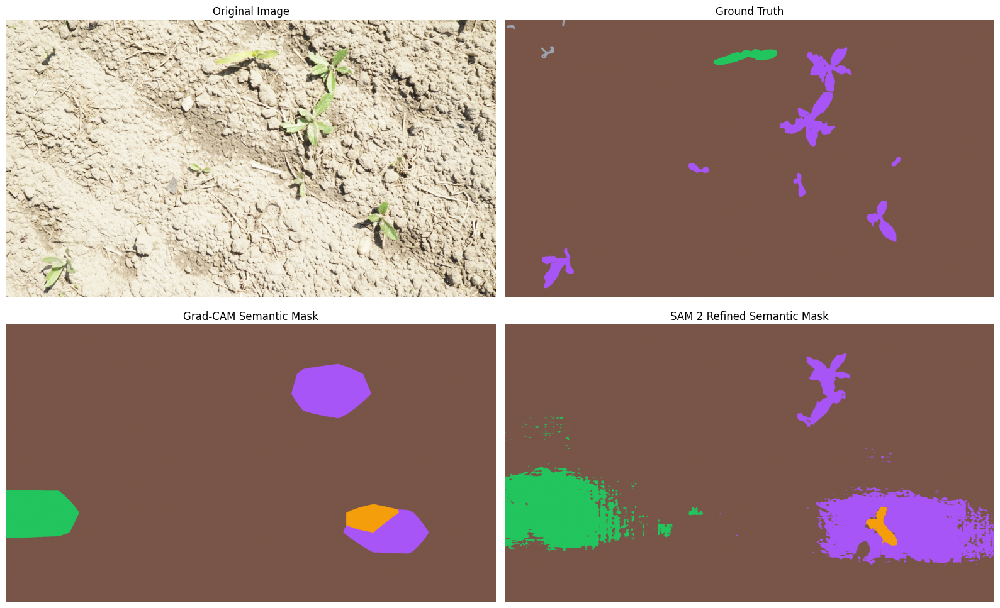

Semantic masks saved successfully!


In [16]:

from matplotlib.colors import ListedColormap, BoundaryNorm

# Semantic segmentation colors
cmap = ListedColormap([
    "#795548",  # Background
    "#22C55E",  # Maize
    "#F59E0B",  # Meadow-grass
    "#A855F7",  # Creeping thistle
    "#9CA3AF"   # Ignored regions
])

norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5, 255.5],
    cmap.N
)

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10)
)

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(gt, cmap=cmap, norm=norm)
axes[0, 1].set_title("Ground Truth")

axes[1, 0].imshow(
    cam_semantic, cmap=cmap, norm=norm
)
axes[1, 0].set_title("Grad-CAM Semantic Mask")

axes[1, 1].imshow(
    sam_semantic, cmap=cmap, norm=norm
)
axes[1, 1].set_title("SAM 2 Refined Semantic Mask")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save qualitative results
Image.fromarray(cam_semantic).save(
    OUTPUT_DIR / "example_cam_mask.png"
)

Image.fromarray(sam_semantic).save(
    OUTPUT_DIR / "example_sam_mask.png"
)

print("Semantic masks saved successfully!")

## 4. Quantitative Segmentation Evaluation

### 4.1 Validation Set Comparison

We evaluate the complete weakly supervised segmentation pipeline on the validation set.

Two approaches are compared:

1. **Grad-CAM baseline:** semantic pseudo-masks generated by thresholding class-specific activation maps.
2. **Grad-CAM + SAM 2:** refined segmentation masks generated using automatic point and bounding-box prompts.

Both approaches use the same trained ResNet18 classifier, class-specific decision thresholds, CAM threshold and validation images.

We compute Intersection over Union (IoU) and Dice score for each target plant category, excluding pixels assigned to the ignore label.

The predicted masks are saved for subsequent analysis and visualization.

This experiment aims to quantify the contribution of SAM 2 to weakly supervised crop and weed segmentation.

In [19]:
# Complete segmentation pipeline
def segment_image(image_name):

    # Generate class activation maps
    rgb, cams, probs = get_image_cams(image_name)

    # Grad-CAM baseline
    cam_mask = create_pseudo_mask(
        cams, BEST_CAM_THRESHOLD
    )

    # Generate SAM 2 masks
    instances = []

    with torch.inference_mode():

        predictor.set_image(rgb)

        for idx, name in enumerate(class_names):

            if probs[idx] < thresholds[idx]:
                continue

            prompts = generate_prompts(
                cams[idx],
                tau=BEST_CAM_THRESHOLD
            )

            for prompt in prompts:

                masks, scores, _ = predictor.predict(
                    point_coords=np.array(
                        [prompt["point"]],
                        dtype=np.float32
                    ),
                    point_labels=np.array([1]),
                    box=np.array(
                        prompt["box"],
                        dtype=np.float32
                    ),
                    multimask_output=True
                )

                best = np.argmax(scores)

                instances.append({
                    "class_id": idx + 1,
                    "mask": masks[best].astype(bool),
                    "sam_score": float(scores[best])
                })

    # Fuse instance masks
    sam_mask, _ = fuse_sam_masks(
        instances, probs, rgb.shape[:2]
    )

    return cam_mask, sam_mask


print("Complete segmentation pipeline ready!")


Complete segmentation pipeline ready!


In [21]:

from tqdm.auto import tqdm

# Create output directories
VAL_DIR = OUTPUT_DIR / "validation_masks"

for method in ["cam", "sam2"]:
    (VAL_DIR / method).mkdir(
        parents=True, exist_ok=True
    )

# Store segmentation statistics
stats = {
    method: {
        "intersection": np.zeros(3),
        "union": np.zeros(3),
        "pred_area": np.zeros(3),
        "gt_area": np.zeros(3)
    }
    for method in ["cam", "sam2"]
}

# Evaluate validation images
for name in tqdm(val_df["image"], desc="Validation"):

    cam_mask, sam_mask = segment_image(name)
    gt = load_target_mask(name)
    valid = gt != 255

    predictions = {
        "cam": cam_mask,
        "sam2": sam_mask
    }

    for method, pred in predictions.items():

        # Save semantic mask
        Image.fromarray(pred).save(
            VAL_DIR / method / f"{Path(name).stem}.png"
        )

        # Accumulate per-class statistics
        for c in range(1, 4):

            p = (pred == c) & valid
            g = (gt == c) & valid

            stats[method]["intersection"][c-1] += (p & g).sum()
            stats[method]["union"][c-1] += (p | g).sum()
            stats[method]["pred_area"][c-1] += p.sum()
            stats[method]["gt_area"][c-1] += g.sum()

# Compute final metrics
results = []

for method, s in stats.items():

    iou = s["intersection"] / np.maximum(s["union"], 1)

    dice = (
        2 * s["intersection"]
        / np.maximum(s["pred_area"] + s["gt_area"], 1)
    )

    for i, name in enumerate(class_names):

        results.append({
            "Method": method,
            "Class": name,
            "IoU": iou[i],
            "Dice": dice[i]
        })

    results.append({
        "Method": method,
        "Class": "Mean",
        "IoU": iou.mean(),
        "Dice": dice.mean()
    })

seg_results = pd.DataFrame(results)

display(seg_results.round(4))

# Save evaluation results
seg_results.to_csv(
    OUTPUT_DIR / "validation_segmentation_results.csv",
    index=False
)

print("Validation completed!")
print("Predicted masks saved:", VAL_DIR)


Validation:   0%|          | 0/44 [00:00<?, ?it/s]

,Method,Class,IoU,Dice
0,cam,Maize,0.0176,0.0345
1,cam,Meadow-grass,0.0034,0.0067
2,cam,Creeping thistle,0.1743,0.2969
3,cam,Mean,0.0651,0.1127
4,sam2,Maize,0.0063,0.0125
5,sam2,Meadow-grass,0.0017,0.0034
6,sam2,Creeping thistle,0.1873,0.3155
7,sam2,Mean,0.0651,0.1105


Validation completed!
Predicted masks saved: /kaggle/working/weedsam_results/validation_masks


### 4.2 Vegetation-Aware Mask Refinement

The initial validation experiment shows that SAM 2 improves the segmentation of Creeping thistle but does not improve the overall foreground mIoU.

Visual analysis reveals that incorrect Grad-CAM prompts frequently lead to background segmentation.

To reduce this problem, we investigate a lightweight vegetation prior based on the Excess Green (ExG) index.

We apply the vegetation filter to both Grad-CAM and SAM 2 semantic masks to distinguish the contribution of color-based filtering from the contribution of SAM 2.

Candidate ExG thresholds are evaluated on the validation set only.

This experiment requires no additional model training and reuses previously generated segmentation masks.

The selected configuration will be frozen before final test evaluation.

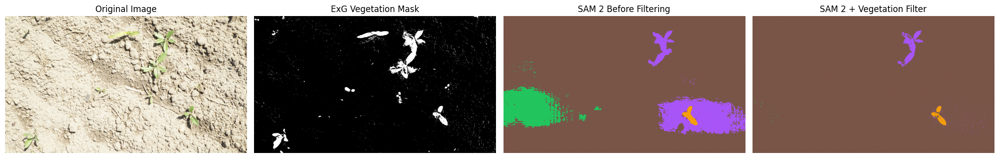

In [22]:

# Compute normalized Excess Green index
def compute_exg(rgb):

    rgb_float = rgb.astype(np.float32) / 255.0

    total = rgb_float.sum(axis=2) + 1e-8

    r = rgb_float[:, :, 0] / total
    g = rgb_float[:, :, 1] / total
    b = rgb_float[:, :, 2] / total

    return 2 * g - r - b


# Filter semantic masks using vegetation prior
def filter_vegetation(mask, exg, threshold=0.05):

    filtered = mask.copy()
    filtered[exg < threshold] = 0

    return filtered


# Test on our example image
exg = compute_exg(rgb)

vegetation_mask = exg >= 0.05

filtered_sam = filter_vegetation(
    sam_semantic, exg, threshold=0.05
)

# Visualize the vegetation filter
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

axes[0].imshow(rgb)
axes[0].set_title("Original Image")

axes[1].imshow(vegetation_mask, cmap="gray")
axes[1].set_title("ExG Vegetation Mask")

axes[2].imshow(sam_semantic, cmap=cmap, norm=norm)
axes[2].set_title("SAM 2 Before Filtering")

axes[3].imshow(filtered_sam, cmap=cmap, norm=norm)
axes[3].set_title("SAM 2 + Vegetation Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:

# Candidate ExG thresholds
exg_thresholds = [0.0, 0.05, 0.10, 0.15]

# Store pixel-level statistics
methods = ["cam", "sam2"]

stats_exg = {
    (method, t): {
        "inter": np.zeros(3),
        "union": np.zeros(3)
    }
    for method in methods
    for t in exg_thresholds
}

# Evaluate saved validation masks
for name in tqdm(val_df["image"], desc="ExG Evaluation"):

    image = np.array(
        Image.open(IMAGE_DIR / name).convert("RGB")
    )

    exg = compute_exg(image)
    gt = load_target_mask(name)
    valid = gt != 255

    for method in methods:

        pred = np.array(Image.open(
            VAL_DIR / method / f"{Path(name).stem}.png"
        ))

        for t in exg_thresholds:

            filtered = filter_vegetation(pred, exg, t)

            for c in range(1, 4):

                p = (filtered == c) & valid
                g = (gt == c) & valid

                stats_exg[(method, t)]["inter"][c-1] += (
                    p & g
                ).sum()

                stats_exg[(method, t)]["union"][c-1] += (
                    p | g
                ).sum()

# Compute evaluation results
rows = []

for (method, t), s in stats_exg.items():

    iou = s["inter"] / np.maximum(s["union"], 1)

    rows.append({
        "Method": method,
        "ExG Threshold": t,
        "Maize": iou[0],
        "Meadow-grass": iou[1],
        "Creeping thistle": iou[2],
        "mIoU": iou.mean()
    })

exg_results = pd.DataFrame(rows)

display(exg_results.round(4))

# Select best SAM 2 vegetation threshold
best_exg = exg_results[
    exg_results["Method"] == "sam2"
].sort_values("mIoU", ascending=False).iloc[0]

print("Best ExG threshold:", best_exg["ExG Threshold"])
print("Best SAM 2 + ExG mIoU:", round(best_exg["mIoU"], 4))

# Save results
exg_results.to_csv(
    OUTPUT_DIR / "vegetation_filter_results.csv",
    index=False
)

ExG Evaluation:   0%|          | 0/44 [00:00<?, ?it/s]

,Method,ExG Threshold,Maize,Meadow-grass,Creeping thistle,mIoU
0,cam,0.00,0.0217,0.0040,0.1828,0.0695
1,cam,0.05,0.1177,0.0093,0.2644,0.1305
2,cam,0.10,0.0770,0.0087,0.2316,0.1057
3,cam,0.15,0.0414,0.0065,0.1809,0.0763
4,sam2,0.00,0.0083,0.0019,0.1951,0.0684
5,sam2,0.05,0.0818,0.0043,0.2985,0.1282
6,sam2,0.10,0.0740,0.0031,0.2648,0.1140
7,sam2,0.15,0.0339,0.0024,0.2117,0.0826


Best ExG threshold: 0.05
Best SAM 2 + ExG mIoU: 0.1282


### 4.3 Interactive Segmentation on New Images

We test the complete WeedSAM pipeline on randomly selected validation images.

For each image, we compare:

- Original RGB image.
- Ground truth segmentation.
- Grad-CAM pseudo-mask.
- SAM 2 refined mask.
- Vegetation-aware SAM 2 mask.

This qualitative experiment helps analyze segmentation performance across different plant species, sizes, and background conditions.

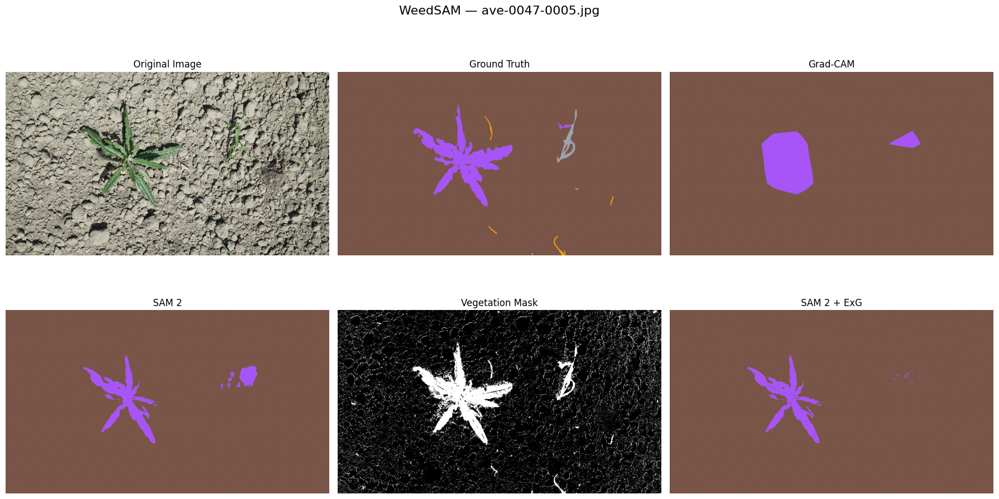

Image: ave-0047-0005.jpg


In [33]:

# Select a random validation image
image_name = val_df.sample(1).iloc[0]["image"]

# Load the original image
rgb_test = np.array(
    Image.open(IMAGE_DIR / image_name).convert("RGB")
)

# Generate segmentation masks
cam_test, sam_test = segment_image(image_name)

# Load ground truth
gt_test = load_target_mask(image_name)

# Apply vegetation filtering
exg_test = compute_exg(rgb_test)

filtered_test = filter_vegetation(
    sam_test, exg_test, threshold=0.05
)

# Visualize results
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

results = [
    (rgb_test, "Original Image"),
    (gt_test, "Ground Truth"),
    (cam_test, "Grad-CAM"),
    (sam_test, "SAM 2"),
    (exg_test >= 0.05, "Vegetation Mask"),
    (filtered_test, "SAM 2 + ExG")
]

for i, (ax, (img, title)) in enumerate(
    zip(axes.ravel(), results)
):
    if i == 0:
        ax.imshow(img)
    elif i == 4:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(img, cmap=cmap, norm=norm)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(f"WeedSAM — {image_name}", fontsize=16)
plt.tight_layout()
plt.show()

print("Image:", image_name)

## 5. Final Test Mask Generation

Following the validation experiments, we freeze all classification, localization, and vegetation filtering parameters.

The selected configuration uses:

- Class-specific classification thresholds: 0.10, 0.10, and 0.15.
- Grad-CAM threshold: 0.70.
- Excess Green threshold: 0.05.
- SAM 2.1 Hiera Tiny with automatic point and box prompts.

We generate semantic segmentation masks for all 46 test images using four configurations:

1. Grad-CAM.
2. Grad-CAM + SAM 2.
3. Grad-CAM + ExG.
4. Grad-CAM + SAM 2 + ExG.

All predictions are exported to persistent experiment outputs for evaluation in Notebook 03.

No hyperparameter tuning is performed using the test set.

In [34]:

# Freeze the selected ExG threshold
BEST_EXG_THRESHOLD = 0.05

TEST_DIR = OUTPUT_DIR / "test_masks"

METHODS = [
    "cam",
    "sam2",
    "cam_exg",
    "sam2_exg"
]

for method in METHODS:
    (TEST_DIR / method).mkdir(
        parents=True, exist_ok=True
    )

# Generate predictions for all test images
for name in tqdm(test_df["image"], desc="Test Segmentation"):

    image = np.array(
        Image.open(IMAGE_DIR / name).convert("RGB")
    )

    # Generate baseline and SAM 2 masks
    cam_mask, sam_mask = segment_image(name)

    # Compute vegetation prior
    exg = compute_exg(image)

    predictions = {
        "cam": cam_mask,
        "sam2": sam_mask,
        "cam_exg": filter_vegetation(
            cam_mask, exg, BEST_EXG_THRESHOLD
        ),
        "sam2_exg": filter_vegetation(
            sam_mask, exg, BEST_EXG_THRESHOLD
        )
    }

    # Save predicted masks
    for method, mask in predictions.items():

        filename = f"{Path(name).stem}.png"

        Image.fromarray(mask.astype(np.uint8)).save(
            TEST_DIR / method / filename
        )

print("All test masks generated successfully!")
print("Output directory:", TEST_DIR)

Test Segmentation:   0%|          | 0/46 [00:00<?, ?it/s]

All test masks generated successfully!
Output directory: /kaggle/working/weedsam_results/test_masks


In [36]:

# Save final experiment configuration
final_config = {
    "class_names": class_names,
    "target_classes": config["target_classes"],
    "classification_thresholds": thresholds.tolist(),
    "cam_threshold": float(BEST_CAM_THRESHOLD),
    "exg_threshold": BEST_EXG_THRESHOLD,
    "sam_model": "SAM 2.1 Hiera Tiny",
    "prompt_min_area": 50,
    "prompt_padding": 0.15,
    "ignore_label": 255,
    "test_images": len(test_df)
}

with open(OUTPUT_DIR / "final_config.json", "w") as f:
    json.dump(final_config, f, indent=4)

# Save dataset split for Notebook 03
test_df.to_csv(
    OUTPUT_DIR / "test.csv",
    index=False
)

# Verify exported masks
for method in METHODS:

    saved_masks = list(
        (TEST_DIR / method).glob("*.png")
    )

    assert len(saved_masks) == len(test_df)

    print(f"{method}: {len(saved_masks)} masks")

print("\nNotebook 02 completed successfully!")

cam: 46 masks
sam2: 46 masks
cam_exg: 46 masks
sam2_exg: 46 masks

Notebook 02 completed successfully!
